In [ ]:
# Purpose:
#   Subclassify monocytes into classical, intermediate, nonclassical, and cytotoxic
#   populations using integrated scRNA-seq and protein (ADT) data.
#
# Summary:
#   - Load Harmony-integrated monocyte Seurat object
#   - Perform cell-cycle scoring and QC visualization
#   - Score cells using published monocyte gene signatures (Science 2017)
#   - Identify and remove likely doublet clusters
#   - Recompute neighbors, UMAP, and clustering on cleaned data
#   - Assign monocyte subtypes based on cluster-level gene signature enrichment,
#     canonical RNA markers (CD14, FCGR3A), and ADT protein expression (CD14, CD16)
#   - Resolve mixed clusters using predicted.celltype.l2 labels
#   - Define final level-3 monocyte identities:
#       Classical, Intermediate, Nonclassical, Cytotoxic Monocytes
#   - Save finalized annotated object

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

In [3]:
packageVersion("Seurat")

[1] ‘5.3.1.0’

# Load

In [4]:
celltype = 'Mono'

In [5]:
obj = qs::qread(glue("data/03_cleandata/itg_{celltype}.qs"))
obj

An object of class Seurat 
28202 features across 111151 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [6]:
exp.mat <- read.table(
    file = "data/geneset/nestorawa_forcellcycle_expressionMatrix.txt",
    header = TRUE, as.is = TRUE, row.names = 1)

s.genes <- cc.genes$s.genes
g2m.genes <- cc.genes$g2m.genes

In [7]:
obj <- CellCycleScoring(obj, 
                        s.features = s.genes, 
                        g2m.features = g2m.genes, 
                        set.ident = TRUE)


Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


# Annotate

In [8]:
colnames(obj@meta.data)

[1] "nFeaturess_RNA"              "nFeaturess_RNA_by_counts"   
 [3] "total_counts"                "total_counts_mt"            
 [5] "pct_counts_mt"               "doublets_pred"              
 [7] "doublets_score"              "nCount_RNA"                 
 [9] "nFeature_RNA"                "percent.mt"                 
[11] "predicted.celltype.l1.score" "predicted.celltype.l1"      
[13] "predicted.celltype.l2.score" "predicted.celltype.l2"      
[15] "predicted.celltype.l3.score" "predicted.celltype.l3"      
[17] "mapping.score"               "RNA_snn_res.0.8"            
[19] "seurat_clusters"             "dataset_name"               
[21] "RNA_snn_res.0.1"             "S.Score"                    
[23] "G2M.Score"                   "Phase"                      
[25] "old.ident"

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



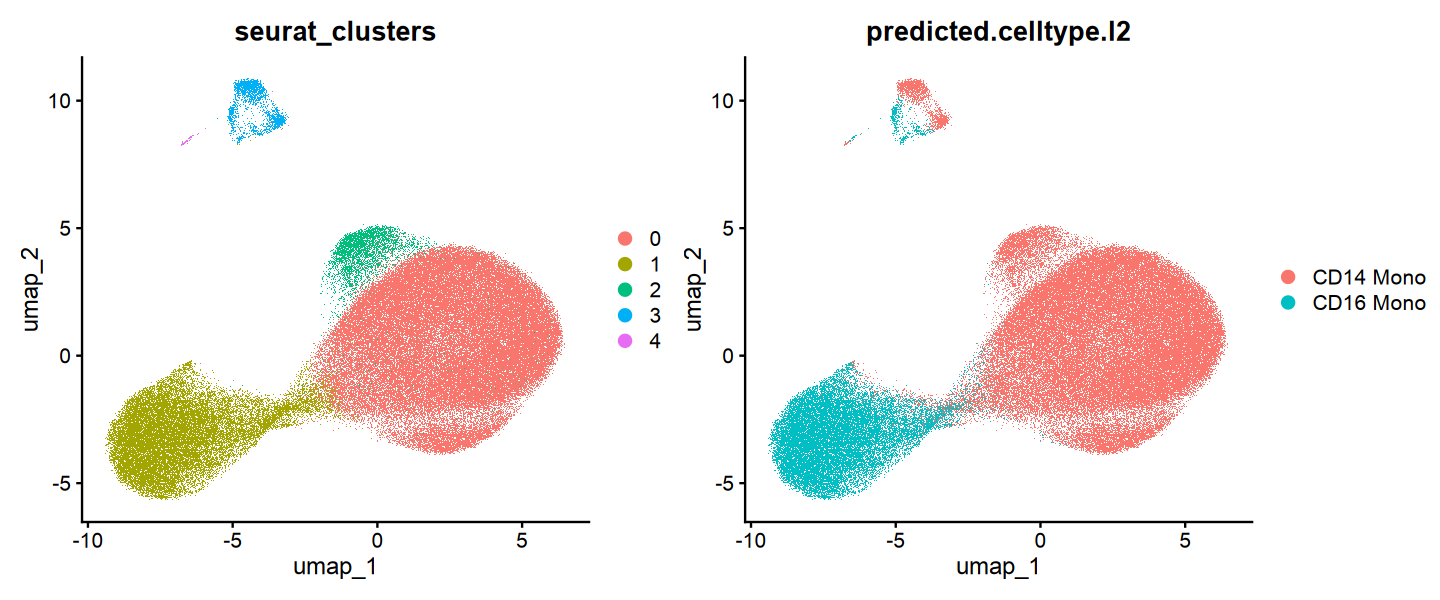

In [9]:
options(repr.plot.width=12, repr.plot.height=5)

DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



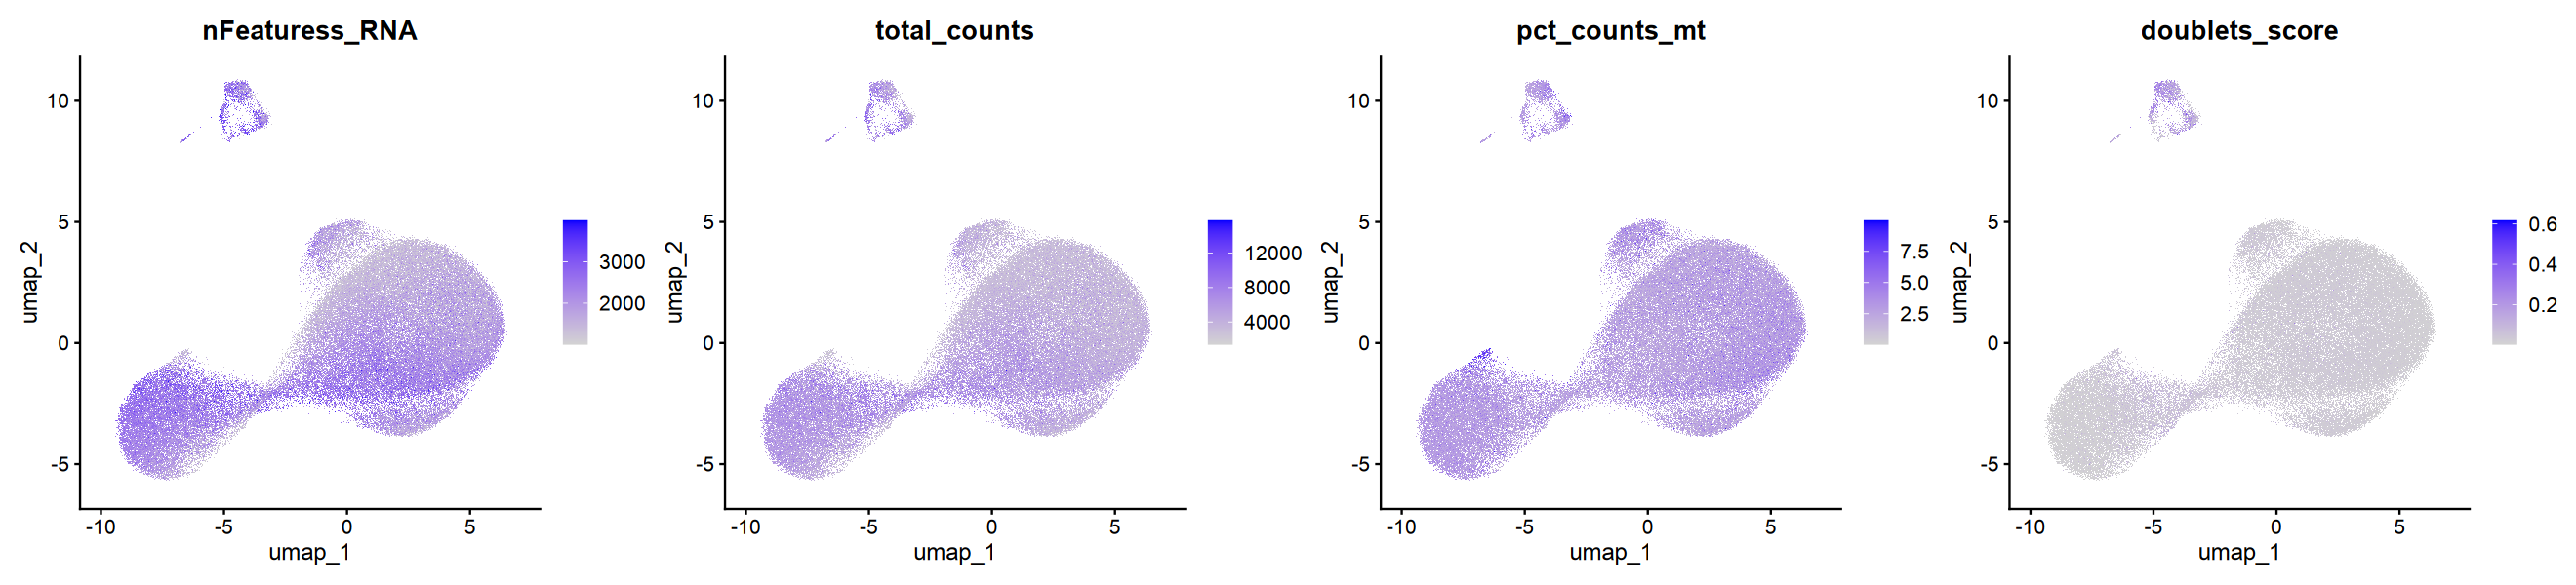

In [10]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(obj, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

Ref:
- Mono1: CD14++CD16-(classical),
- Mono2: CD14+CD16++(nonclassical),
- Mono3: cell cycle, differentiation, trafficking (MXD1, CXCR1, CXCR2, VNN2)
- Mono4: cytotoxic (PRF1, GNLY, CTSW) + coexpressing Mono1 genes

In background, they mentioned `For monocytes, we sampled LIN– CD14 lo/++ cells(including classicalCD14++ CD16– , intermediate CD14++ CD16+ , and nonclassical CD14+CD16++)` 

In [13]:
marker_df <- read.table("data/04_markergenes/science2017_monocyte_markers.csv", 
                        sep=',', header=1,
                        check.names=FALSE)

# 2. Get unique clusters
clusters <- unique(marker_df$Cluster.ID)

# 3. Create a named list of gene sets by cluster (e.g., for Mono1, Mono2, ...)
marker_list <- lapply(clusters, 
                      function(cl) marker_df$Gene.ID[marker_df$Cluster.ID == cl])
names(marker_list) <- clusters

marker_list                   

$Mono1
  [1] "CD14"         "VCAN"         "S100A8"       "S100A9"       "FCN1"        
  [6] "ITGB2"        "LRP1"         "CSF3R"        "TKT"          "LYZ"         
 [11] "APLP2"        "FPR1"         "CD36"         "S100A12"      "CLEC4E"      
 [16] "ITGAM"        "SLC2A3"       "CTSD"         "NEAT1"        "PTAFR"       
 [21] "TREM1"        "NAIP"         "NCF1"         "FCGR2A"       "SCPEP1"      
 [26] "CTSA"         "NLRP3"        "ACSL1"        "SDCBP"        "SLC11A1"     
 [31] "IRS2"         "VNN2"         "DPYD"         "CLEC7A"       "BST1"        
 [36] "PLBD1"        "PYGL"         "QPCT"         "BC013828"     "CD163"       
 [41] "AQP9"         "PELI1"        "FAM198B"      "GAS7"         "STAB1"       
 [46] "CDA"          "DOK3"         "IRAK3"        "PLAUR"        "AL137655"    
 [51] "LILRA6"       "TLR4"         "AX747598"     "TLR2"         "AGTRAP"      
 [56] "CRISPLD2"     "CCR1"         "NFAM1"        "ETS2"         "RAB27A"      
 [61] "BNIP3L"       "HPSE"         "PER1"         "MEGF9"        "CD300E"      
 [66] "CYP1B1"       "FCAR"         "SOD2"         "UPP1"         "IER3"        
 [71] "C5AR1"        "NLRP12"       "SMA"          "DMXL2"        "NCF1B"       
 [76] "CREB5"        "CR1"          "ALDH1A1"      "ASGR1"        "FNDC3B"      
 [81] "DUSP6"        "TOM1"         "CDC42EP3"     "ZBTB16"       "DYSF"        
 [86] "KCNE3"        "CD93"         "CEBPD"        "FCGR1A"       "PLEKHM1"     
 [91] "CPM"          "MPP7"         "AK302511"     "IL1B"         "PFKFB3"      
 [96] "PLD3"         "SMA3"         "F13A1"        "G0S2"         "LOC100133161"
[101] "PHF21A"       "TLR8"         "CLMN"         "TNFAIP3"     

$Mono2
 [1] "LAIR2"    "ASAH1"    "APOBEC3A" "TSPAN14"  "LIPA"     "CYTIP"   
 [7] "SIGLEC10" "LILRB1"   "EMR1"     "TTYH3"    "CAMKK2"   "CX3CR1"  
[13] "C3AR1"    "BC013828" "RASGEF1B" "BIRC3"    "PLIN2"    "CD300C"  
[19] "CD83"     "XYLT1"    "KLF2"     "FBP1"    

$Mono3
  [1] "G0S2"          "NAMPT"         "NEAT1"         "AL137655"     
  [5] "CSF3R"         "FCGR3B"        "SRGN"          "TREM1"        
  [9] "TNFRSF10C"     "MXD1"          "SOD2"          "CXCR2"        
 [13] "SLC25A37"      "S100A8"        "FPR1"          "ITM2B"        
 [17] "MNDA"          "VNN2"          "SDCBP"         "CXCR1"        
 [21] "S100A9"        "AQP9"          "SORL1"         "ACSL1"        
 [25] "AX747598"      "R3HDM4"        "NCF1"          "IFITM2"       
 [29] "FCGR2A"        "XPO6"          "GCA"           "C5AR1"        
 [33] "TKT"           "PELI1"         "SLC2A3"        "CLEC4E"       
 [37] "MMP25"         "GLUL"          "CD14"          "LOC388312"    
 [41] "NCF1C"         "VMP1"          "RTN3"          "ACTN1"        
 [45] "PTAFR"         "S100A12"       "SEC14L1"       "DQ574721"     
 [49] "LITAF"         "TLR2"          "SHKBP1"        "LIMK2"        
 [53] "LOC100505702"  "PYGL"          "RNF24"         "DNAJC25-GNG10"
 [57] "IL8"           "FPR2"          "LOC731275"     "SLC12A6"      
 [61] "IL1R2"         "VNN3"          "CFD"           "VCAN"         
 [65] "BC013828"      "NAIP"          "ZBTB16"        "BCL2A1"       
 [69] "FAM129A"       "PLAUR"         "FNDC3B"        "FP15737"      
 [73] "SEPX1"         "LOC100133161"  "PER1"          "FBXL5"        
 [77] "IL17RA"        "TLR4"          "IGF2R"         "ITGAM"        
 [81] "HIST1H2AC"     "LRP1"          "KREMEN1"       "C12ORF35"     
 [85] "PRRG4"         "CR1"           "RAB27A"        "LOC100505815" 
 [89] "BST1"          "NUMB"          "USP15"         "CDA"          
 [93] "IER3"          "ACADSB"        "DYSF"          "PXN"          
 [97] "PDP2"          "TNFRSF1A"      "LRG1"          "LOC91948"     
[101] "FLJ45445"      "SMAP2"         "LOC643802"     "NINJ1"        
[105] "ABTB1"         "CCNY"          "TMEM154"       "CCR1"         
[109] "CARD8"         "TACC3"         "TMEM71"        "PTGS2"        
[113] "HPSE"          "C3ORF72"       "FAM157A"       "AK130076"     

In [14]:
obj <- AddModuleScore(
  object = obj,
  features = marker_list,
  name = paste0(names(marker_list), "_score")
)

Warning message:
“The following features are not present in the object: BC013828, FAM198B, AL137655, AX747598, SMA, NCF1B, AK302511, SMA3, LOC100133161, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: EMR1, BC013828, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: AL137655, AX747598, LOC388312, NCF1C, DQ574721, LOC100505702, DNAJC25-GNG10, IL8, LOC731275, BC013828, FAM129A, FP15737, SEPX1, LOC100133161, C12ORF35, LOC100505815, LOC91948, FLJ45445, LOC643802, C3ORF72, FAM157A, AK130076, AZGP1P1, FAM115C, GPR97, FAM198B, NCF1B, BC048113, AX747405, PCNX, LPPR2, FAM157B, AK302511, AK091866, DQ580909, LOC649305, MRS2P2, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: KLRC4-KLRK1, TCRBV3S1, GPR56, RARRES3, BC013828, INADL, LOC388692, FAIM3, PAPD5, SEPX1, AK094156, LOC100216546, BC051736, LOC374443, DQ573668, FXYD6-FXYD

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



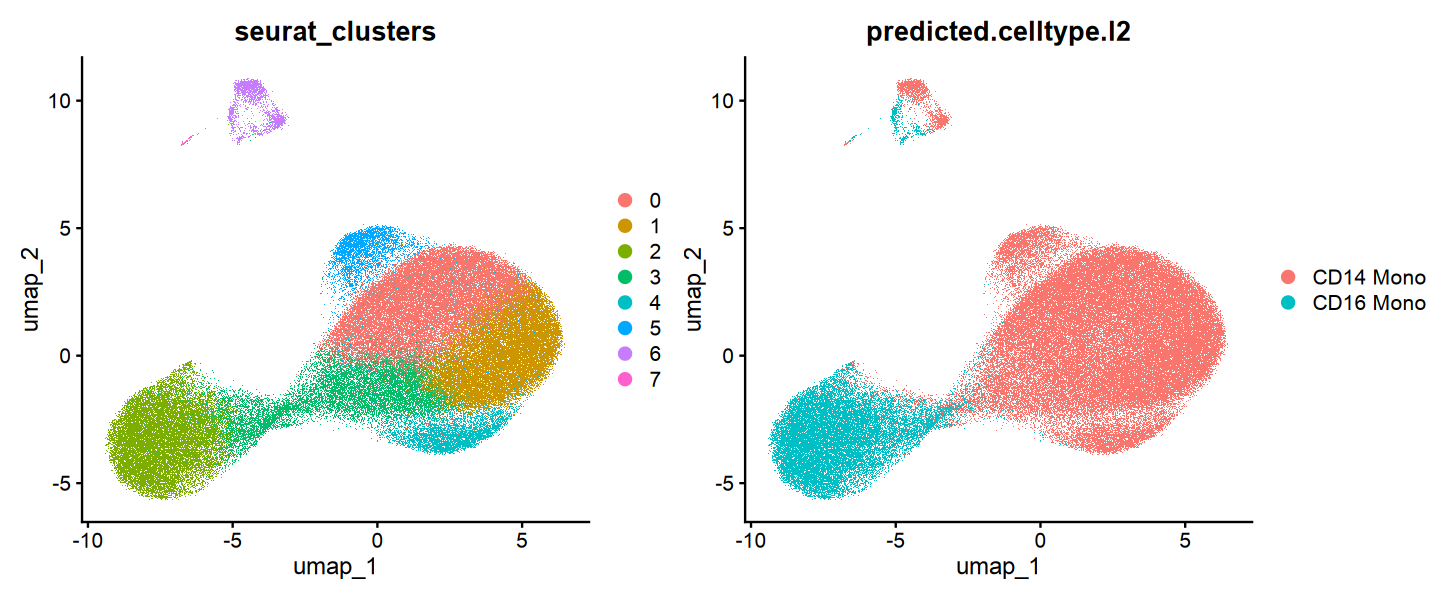

In [19]:
options(repr.plot.width=12, repr.plot.height=5)

# obj <- FindClusters(obj, resolution = .3)

DimPlot(obj, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

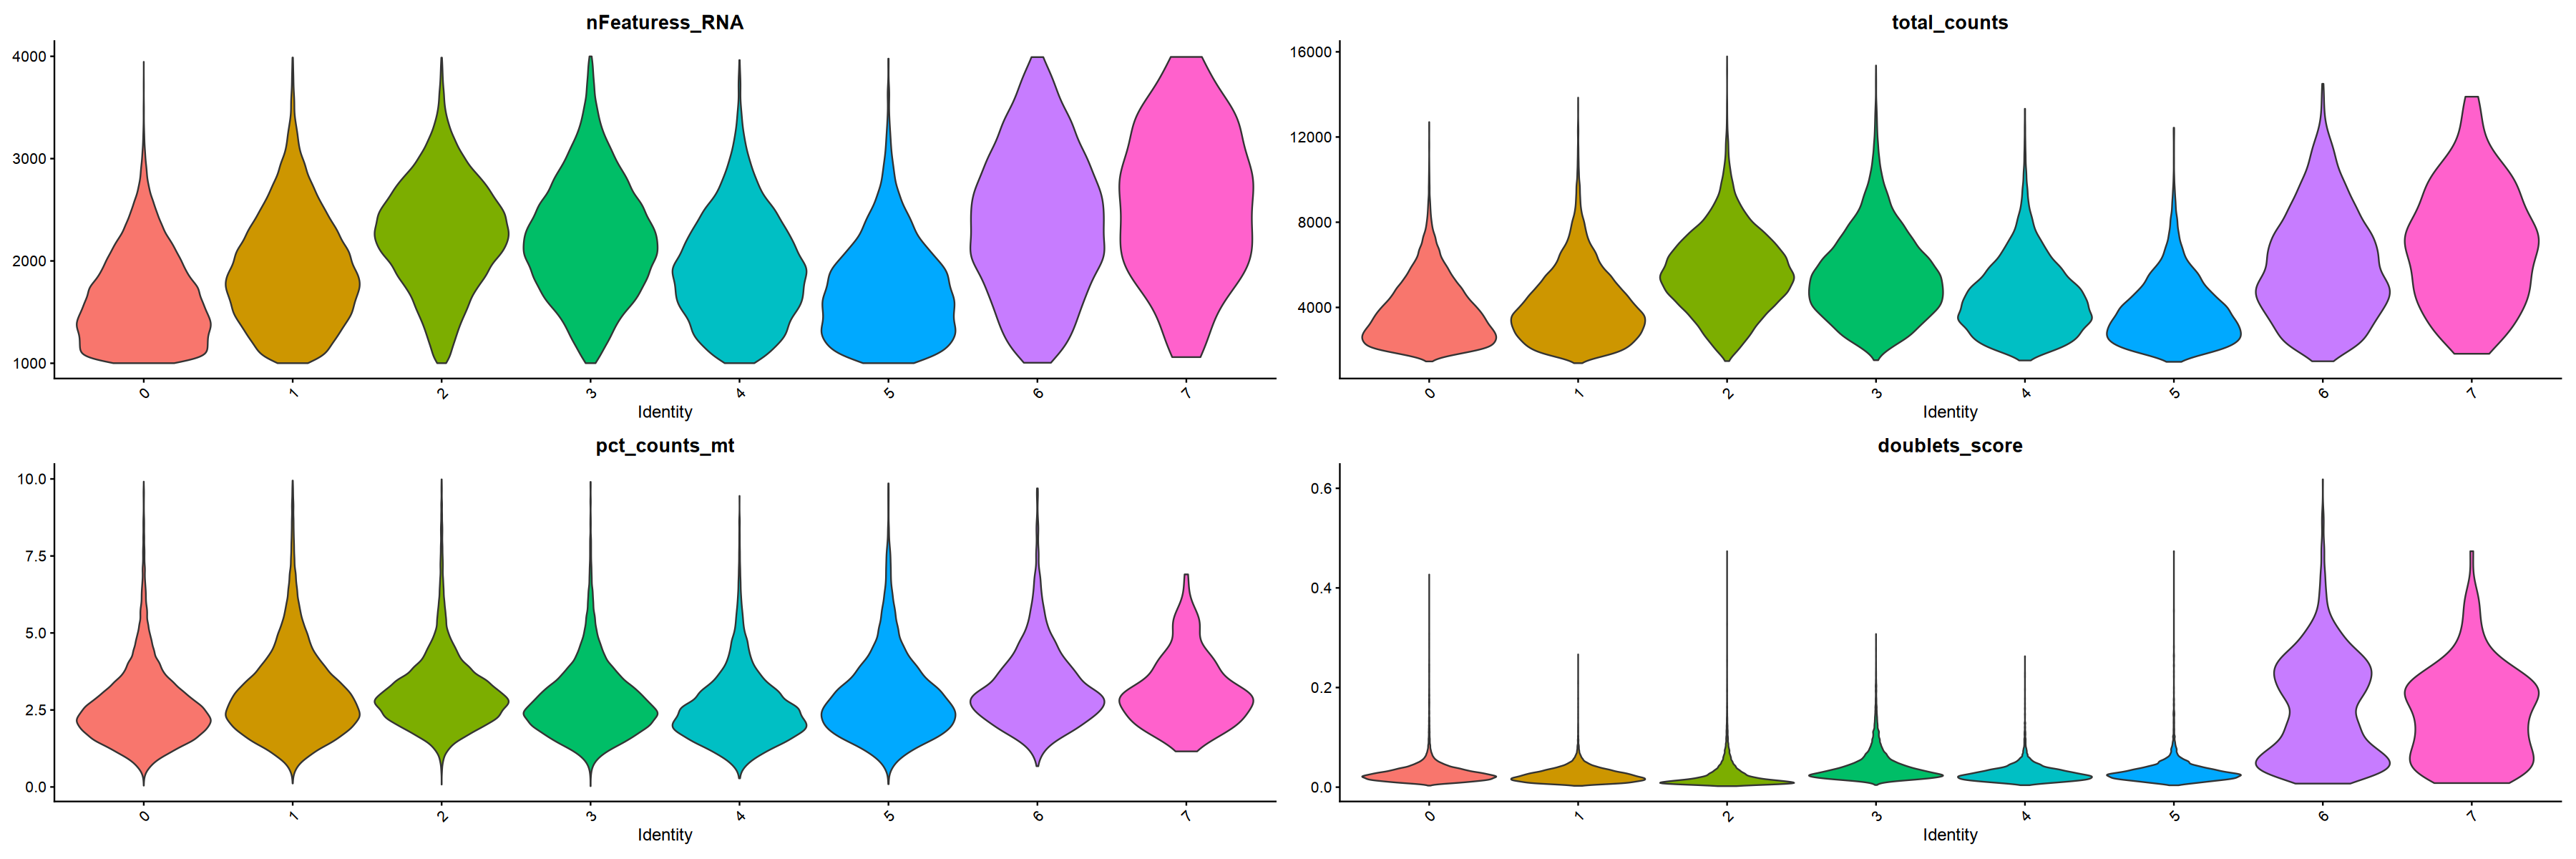

In [20]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

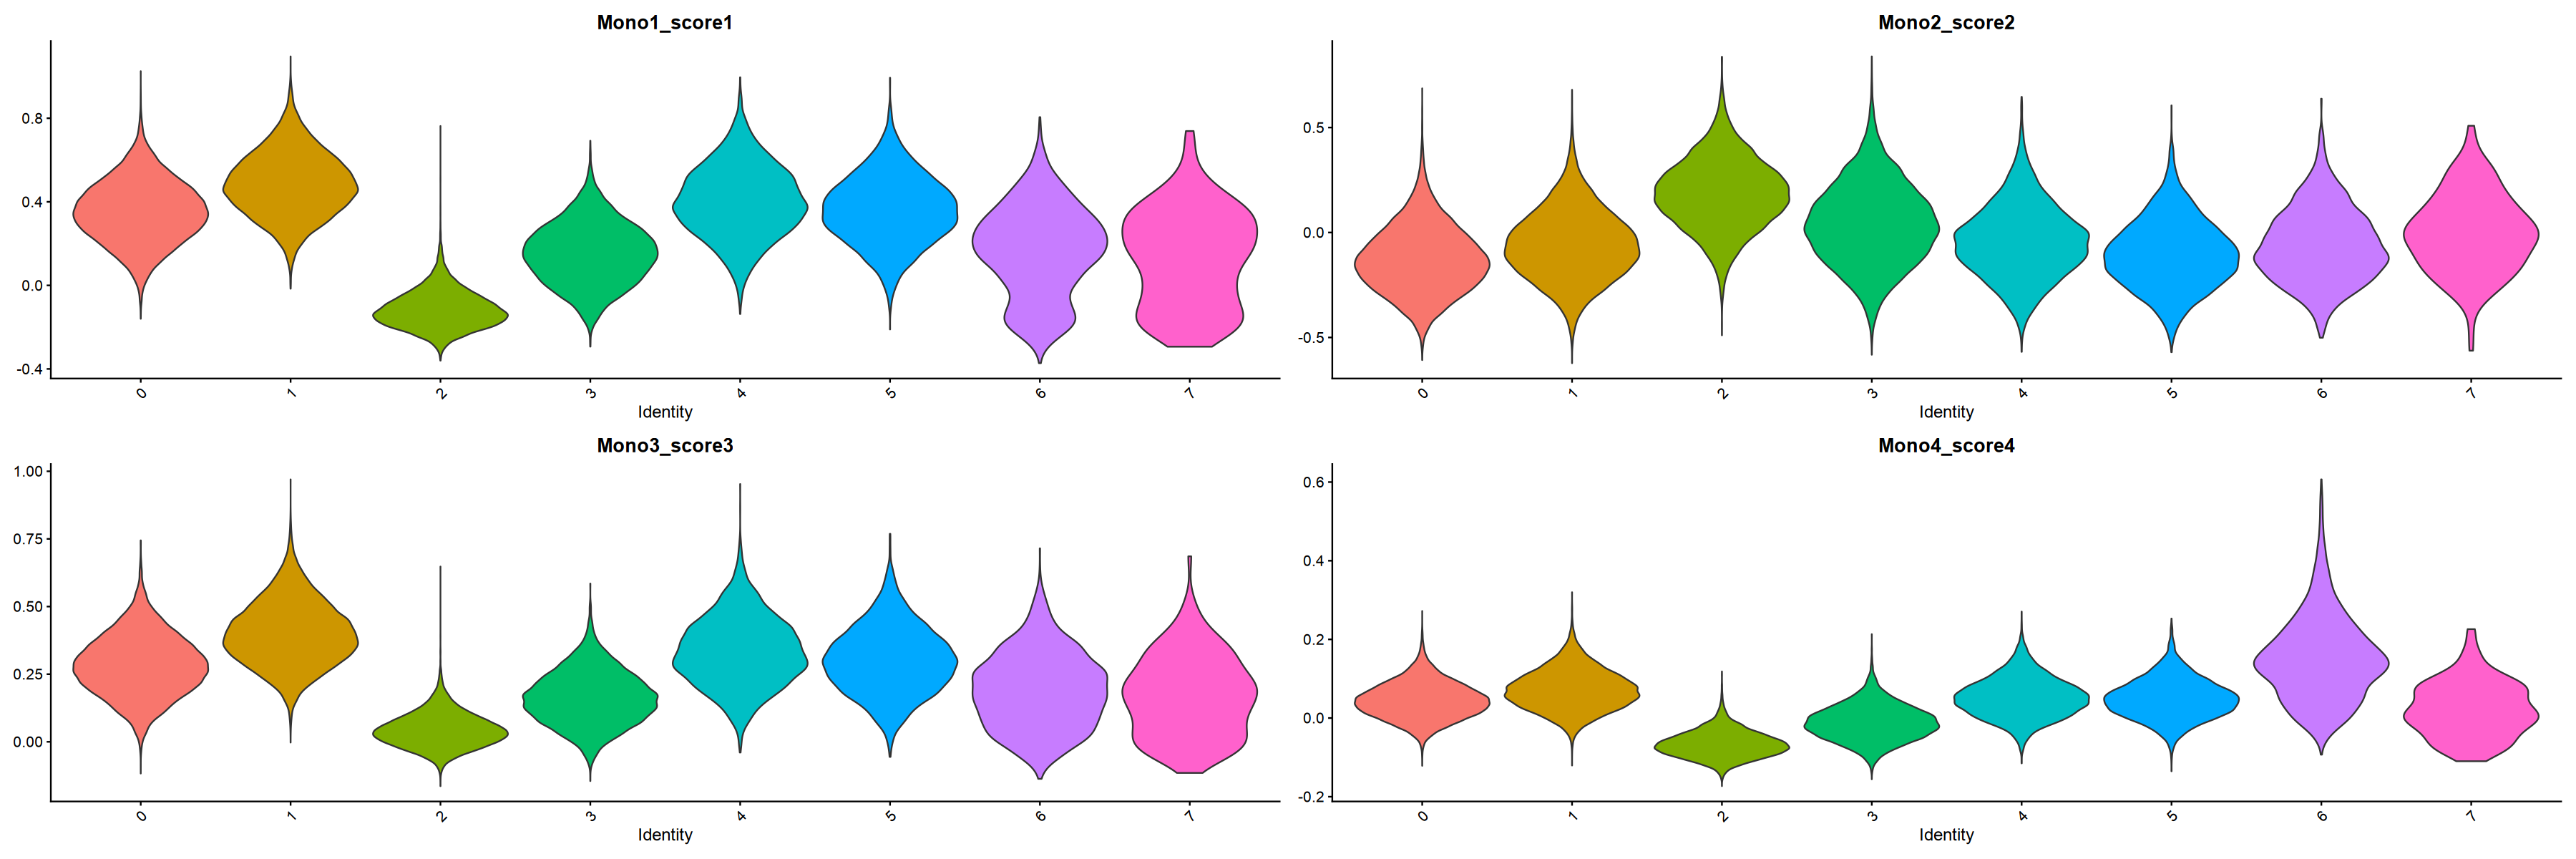

In [17]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(obj, 
        features = c('Mono1_score1',
           'Mono2_score2',
           'Mono3_score3',
           'Mono4_score4'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

In [21]:
# though 6 and 7 have higher doublet score, 6 has much higher cytotoxic Monocyte signature
# thus exclude 7 as doublet

ft = subset(x = obj, 
            subset = !(seurat_clusters %in% c(7)))

ft

An object of class Seurat 
28202 features across 110990 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [22]:
ft <- FindNeighbors(ft, dims = 1:30, reduction = "harmony")
ft <- RunUMAP(ft, dims = 1:30, reduction = "harmony")

Computing nearest neighbor graph

Computing SNN

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
15:01:05 UMAP embedding parameters a = 0.9922 b = 1.112

15:01:05 Read 110990 rows and found 30 numeric columns

15:01:05 Using Annoy for neighbor search, n_neighbors = 30

15:01:05 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

15:01:22 Writing NN index file to temp file /tmp/Rtmp2xzx1Q/file6e2f5718c1306

15:01:22 Searching Annoy index using 1 thread, search_k = 3000

15:02:31 Annoy recall = 100%

15:02:32 Commencing smooth kNN distance c

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 110990
Number of edges: 2187863

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8791
Number of communities: 16
Elapsed time: 54 seconds


9 singletons identified. 7 final clusters.

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



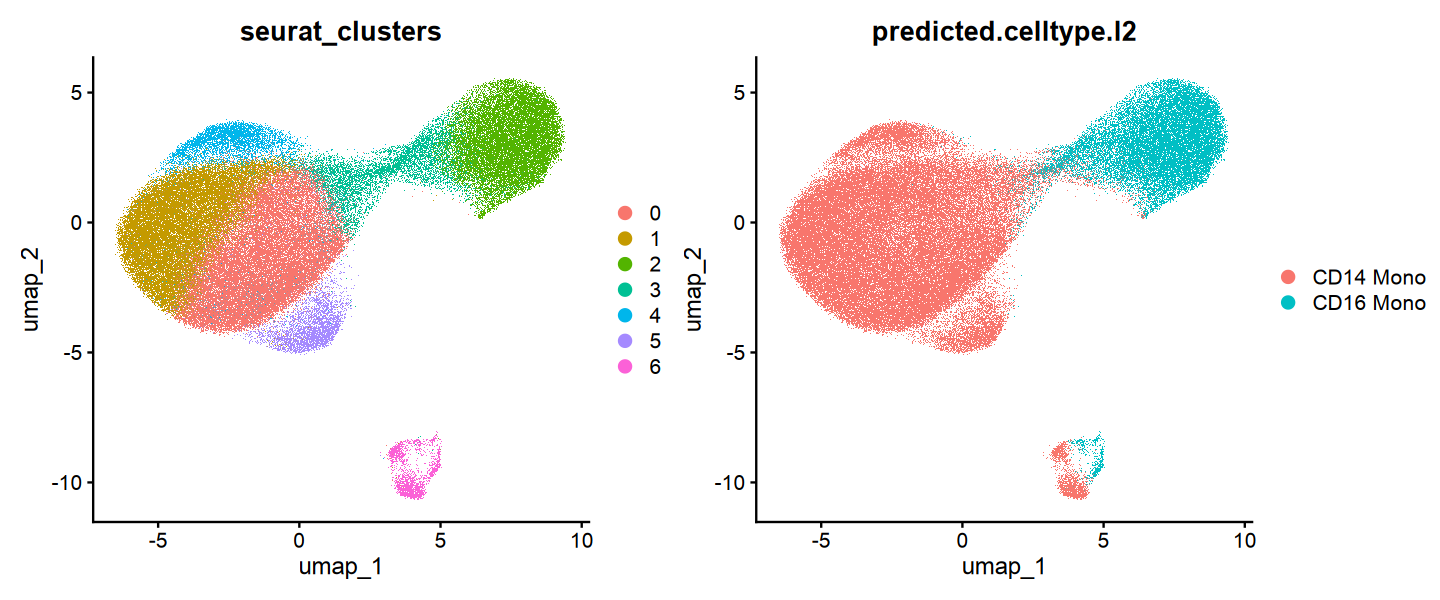

In [60]:
options(repr.plot.width=12, repr.plot.height=5)

ft <- FindClusters(ft, resolution = .3)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



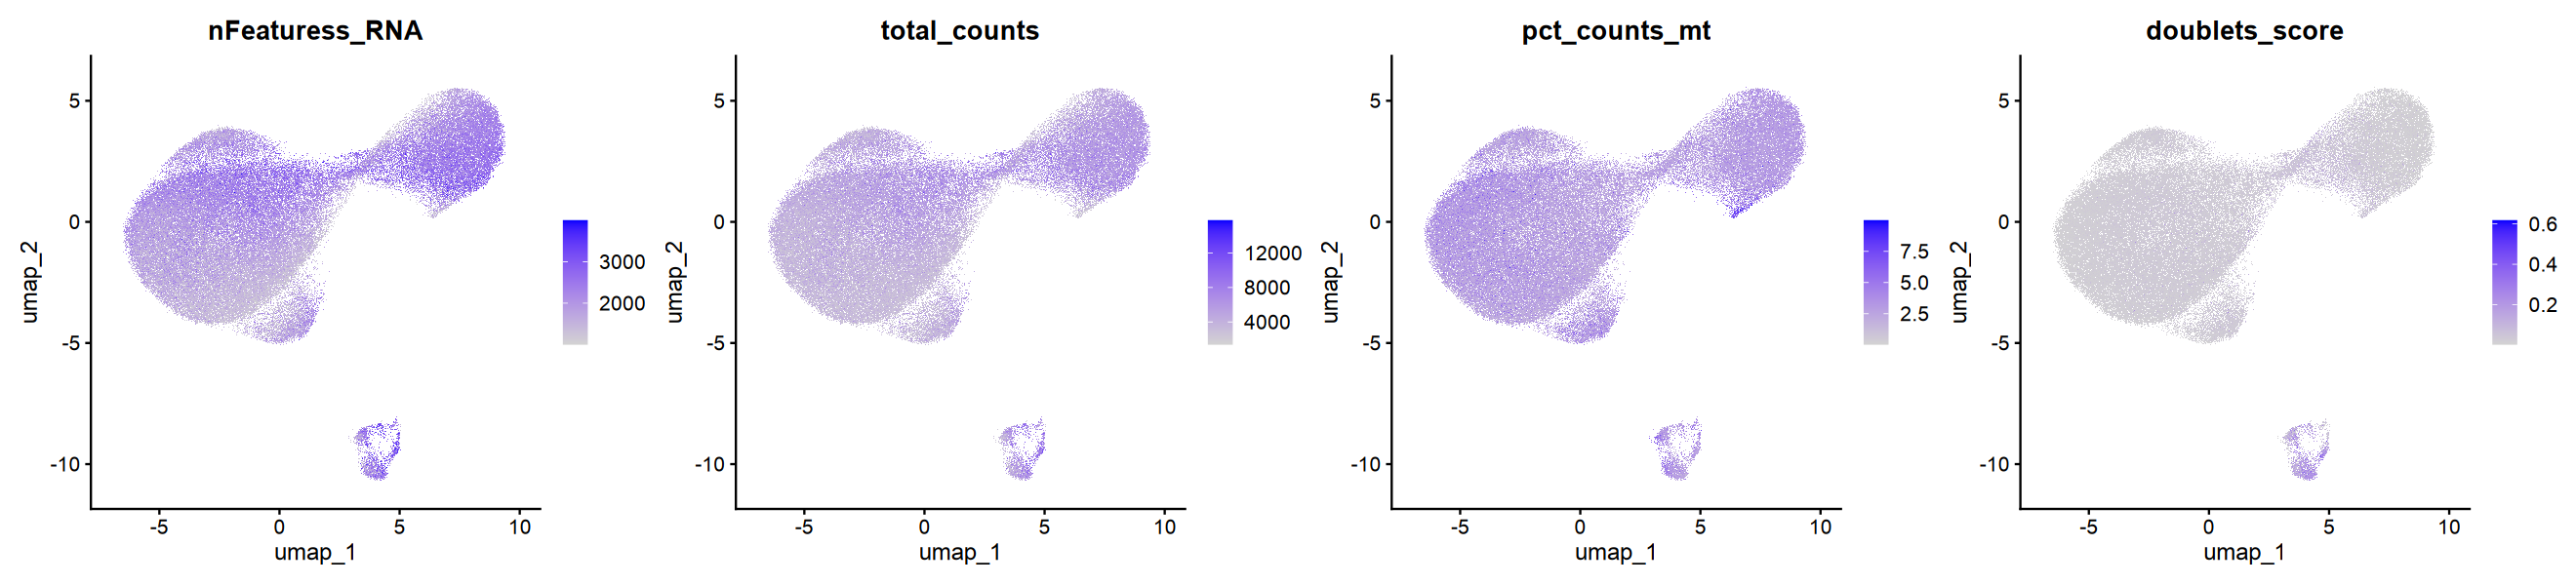

In [64]:
options(repr.plot.width=22, repr.plot.height=5)

FeaturePlot(ft, 
            features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
            reduction = 'umap', ncol=4)

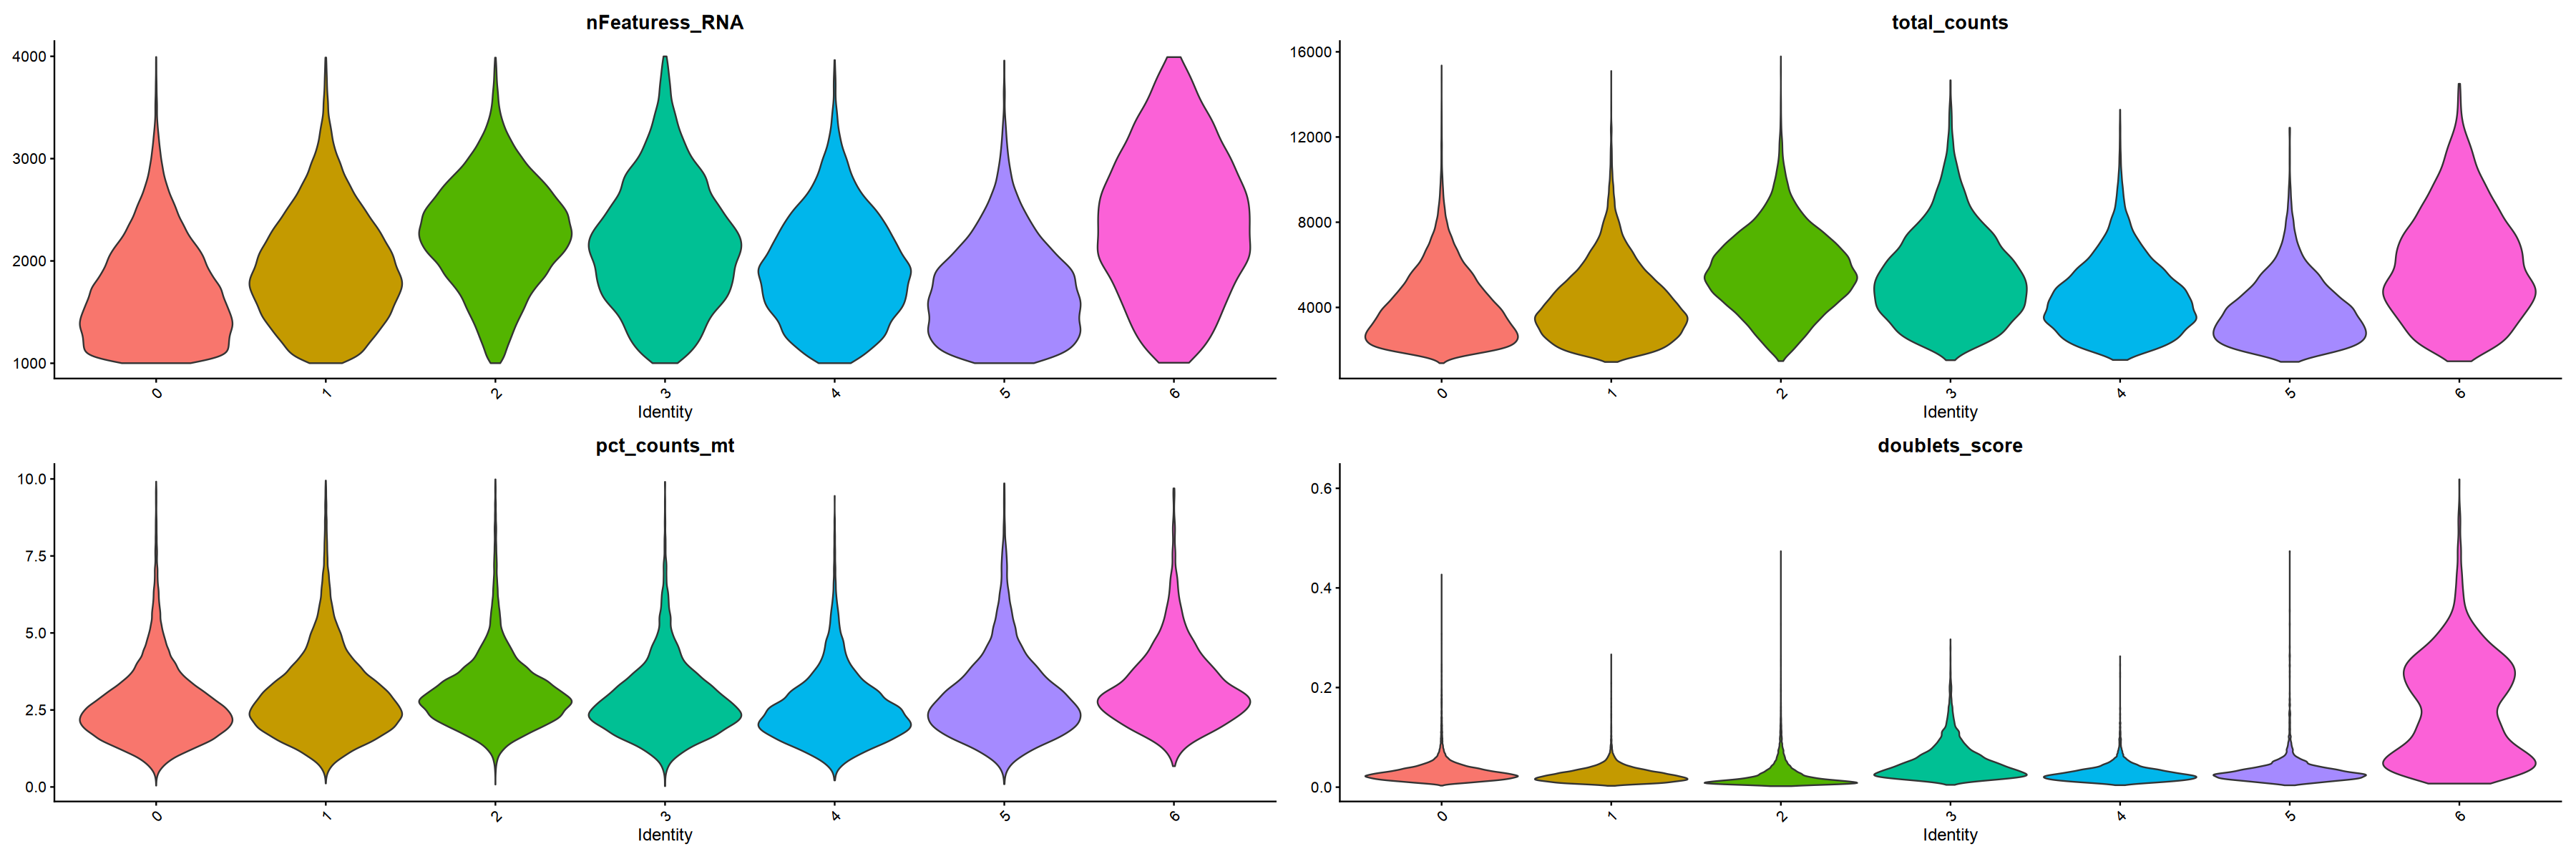

In [65]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('nFeaturess_RNA','total_counts','pct_counts_mt','doublets_score'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

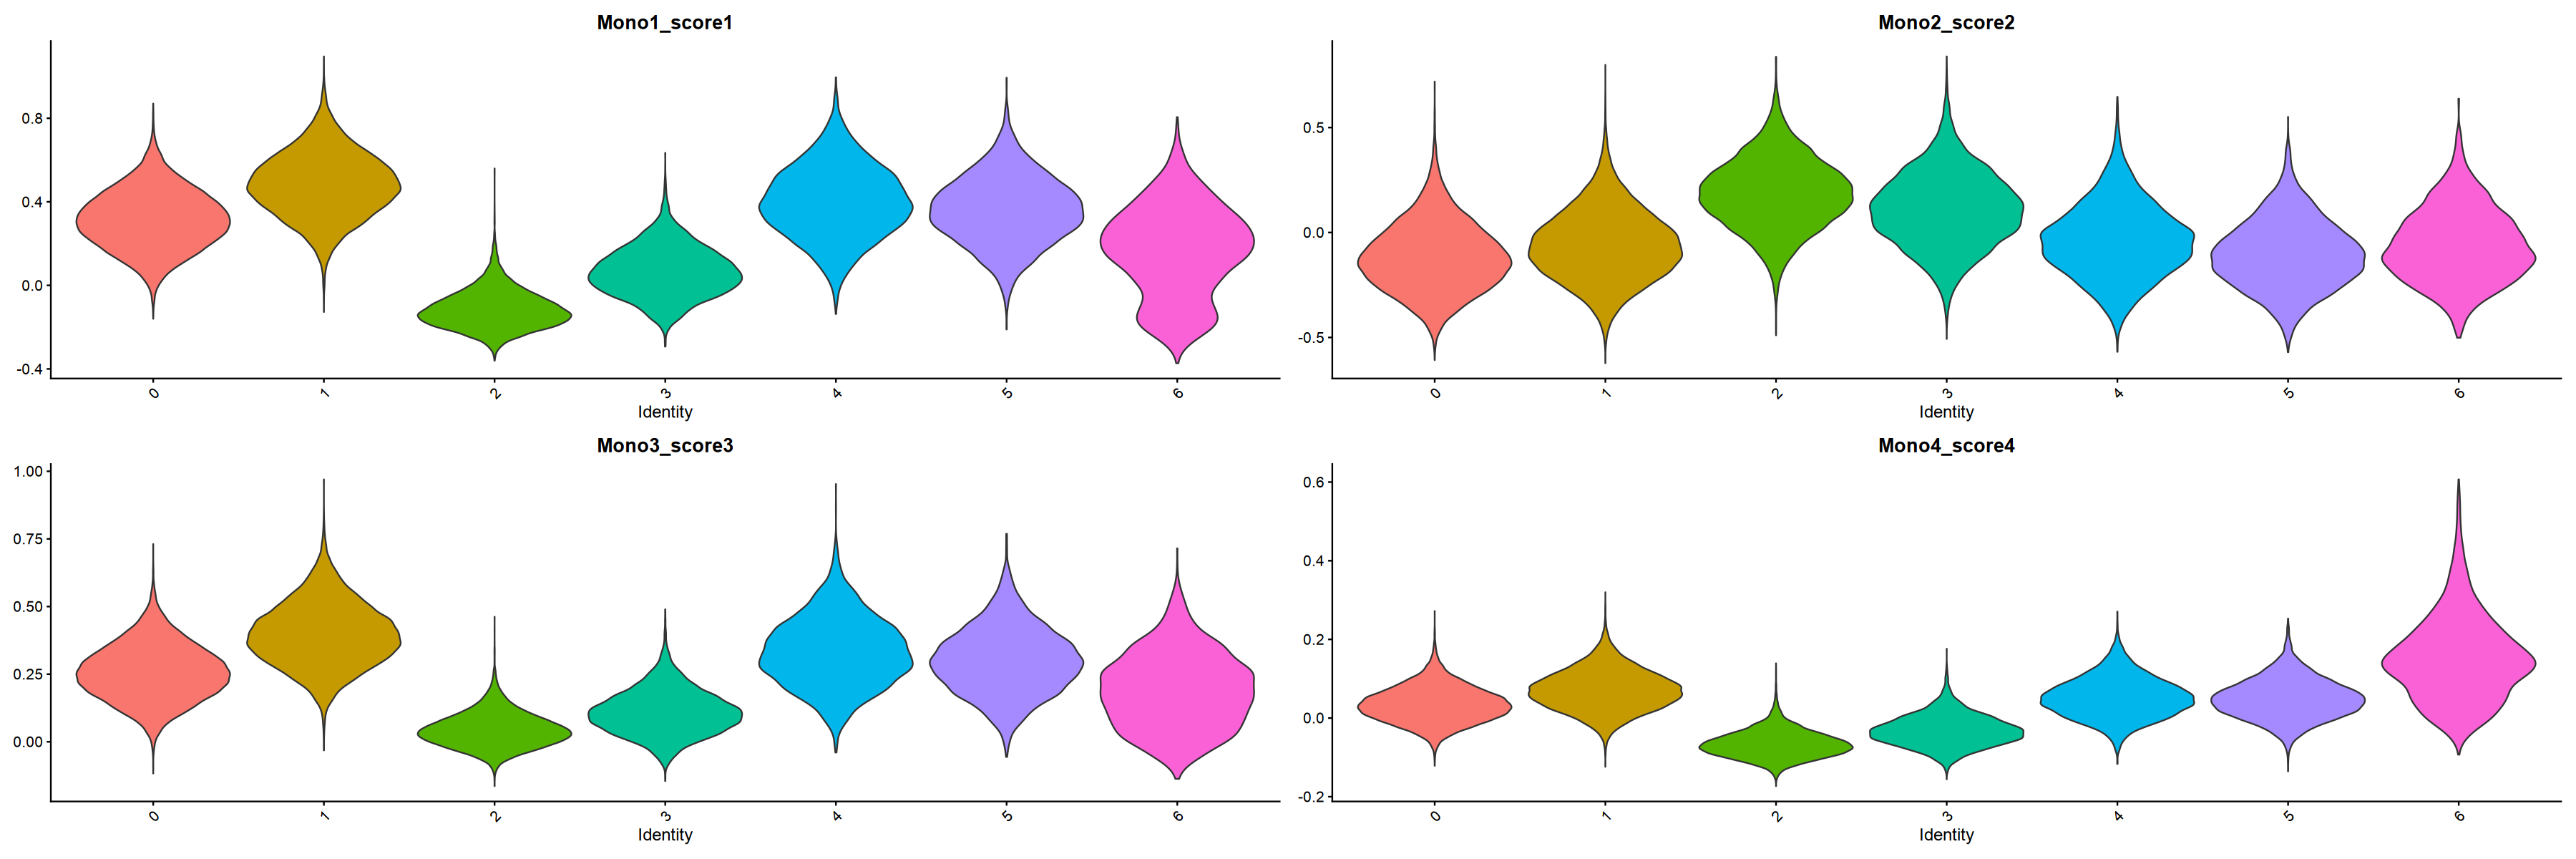

In [66]:
options(repr.plot.width=30, repr.plot.height=10)
# py scrublet calculation
VlnPlot(ft, 
        features = c('Mono1_score1',
           'Mono2_score2',
           'Mono3_score3',
           'Mono4_score4'),  
        group.by='seurat_clusters', 
        ncol=2, pt.size=0)

In [51]:
score_mat <- ft@meta.data[, c('Mono1_score1', 'Mono2_score2', 'Mono3_score3', 'Mono4_score4')]
score_mat_z <- scale(score_mat)

max_col <- colnames(score_mat_z)[apply(score_mat_z, 1, which.max)]
mono_assignment <- sub("_score.*", "", max_col)

ft@meta.data$Mono_max_zcol <- mono_assignment
table(ft@meta.data$Mono_max_zcol)


Mono1 Mono2 Mono3 Mono4 
23483 40286 21623 25598 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



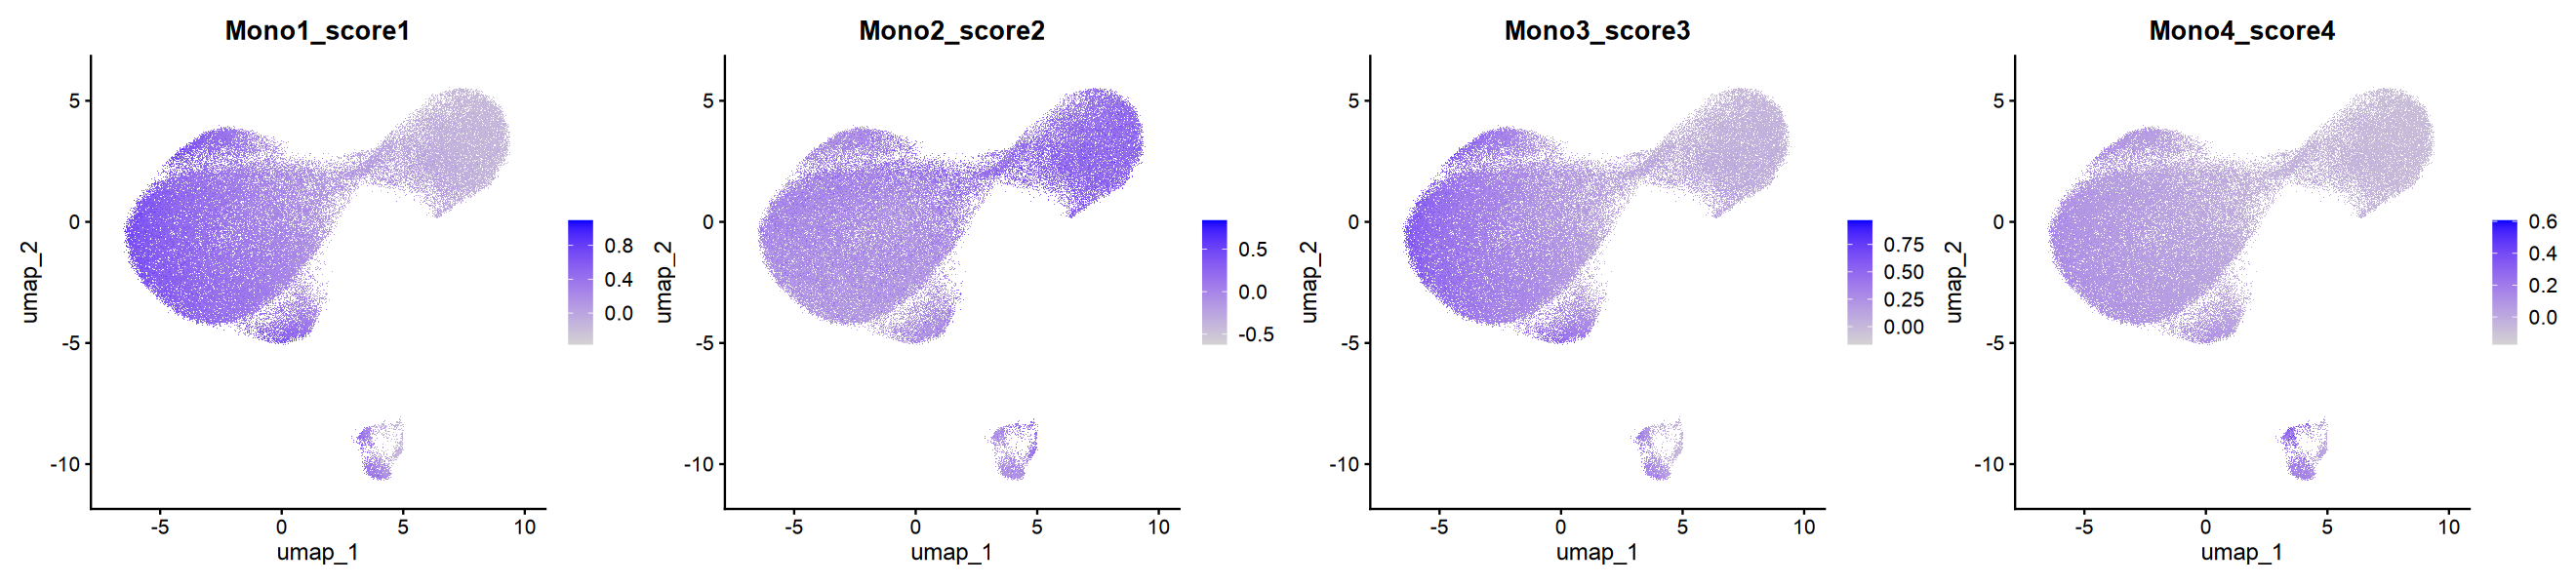

In [28]:
options(repr.plot.width=22, repr.plot.height=5)

ft_plt = c('Mono1_score1',
           'Mono2_score2',
           'Mono3_score3',
           'Mono4_score4')

FeaturePlot(ft, 
            features = ft_plt,  
            reduction = 'umap', ncol=4)

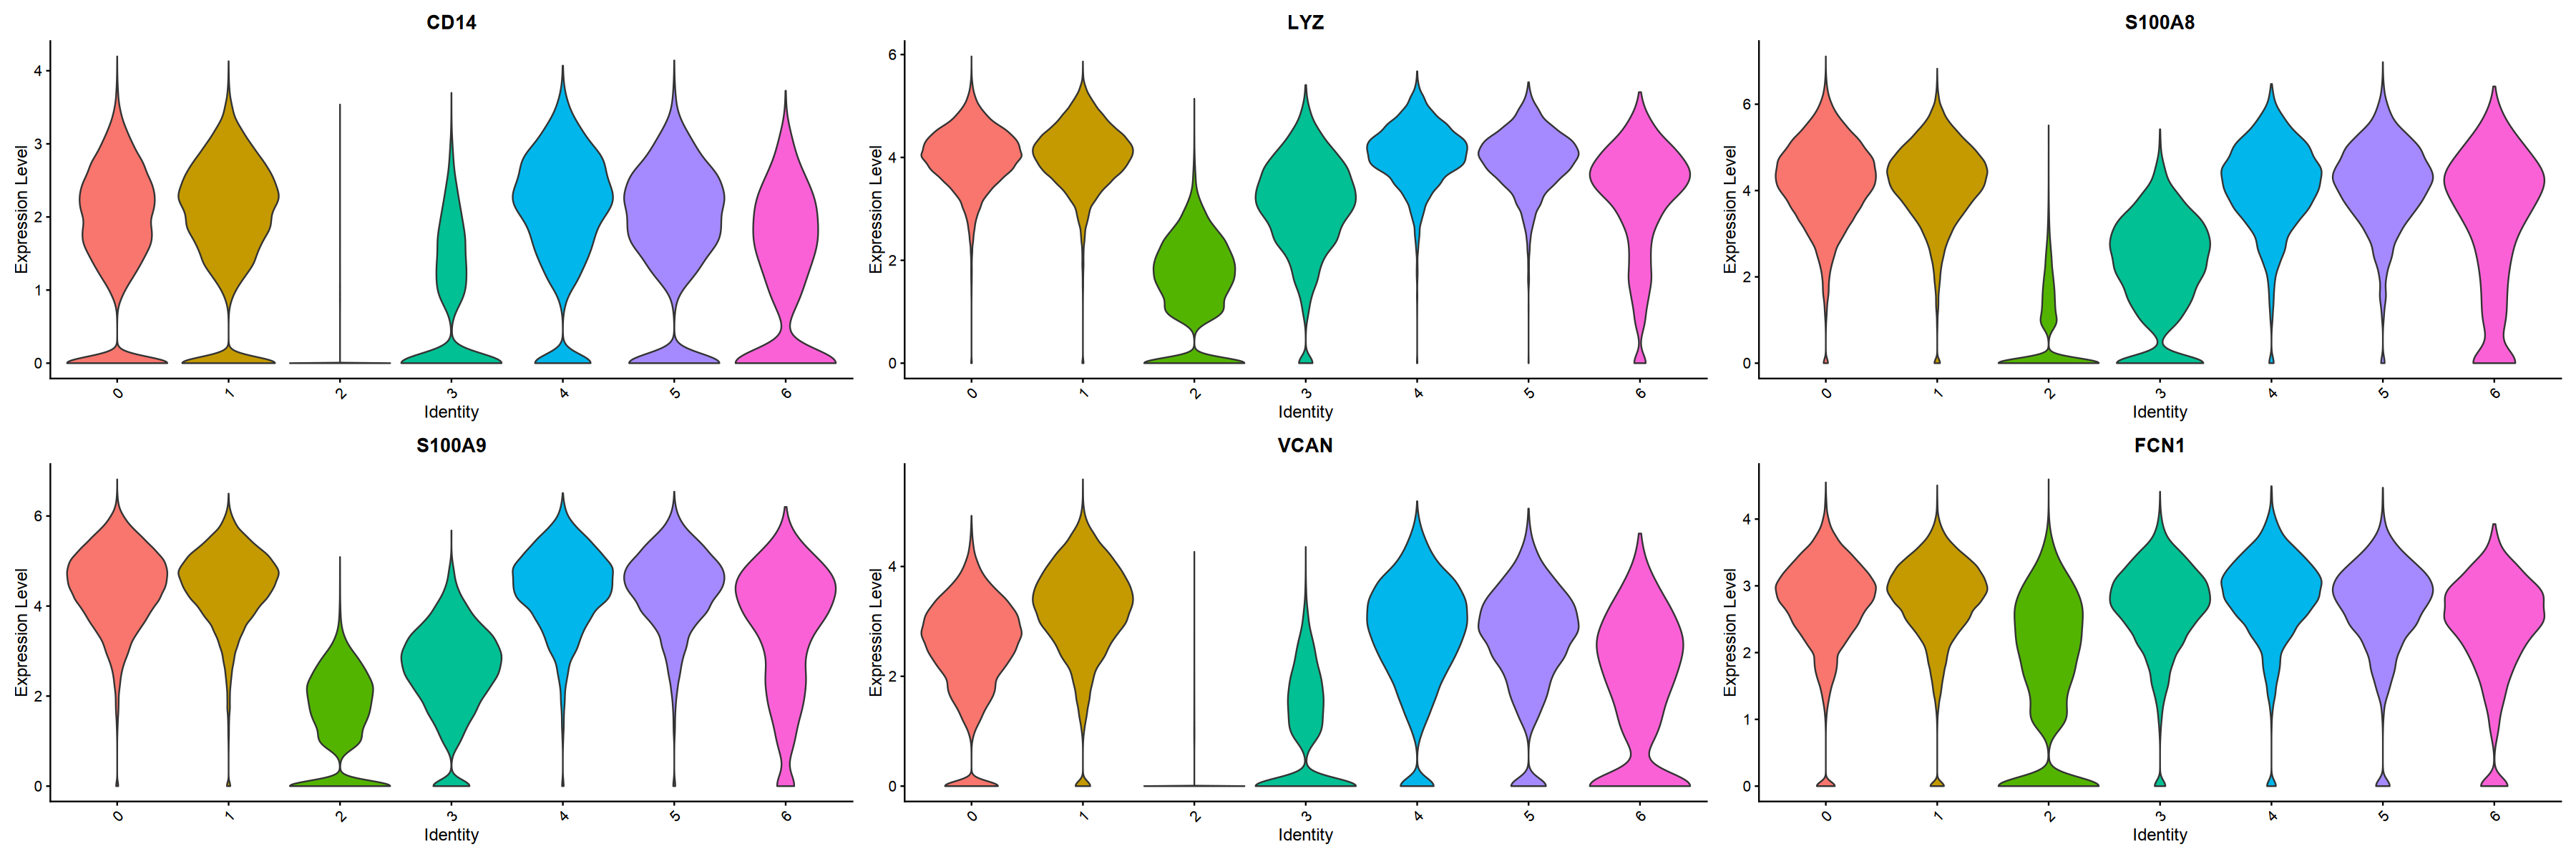

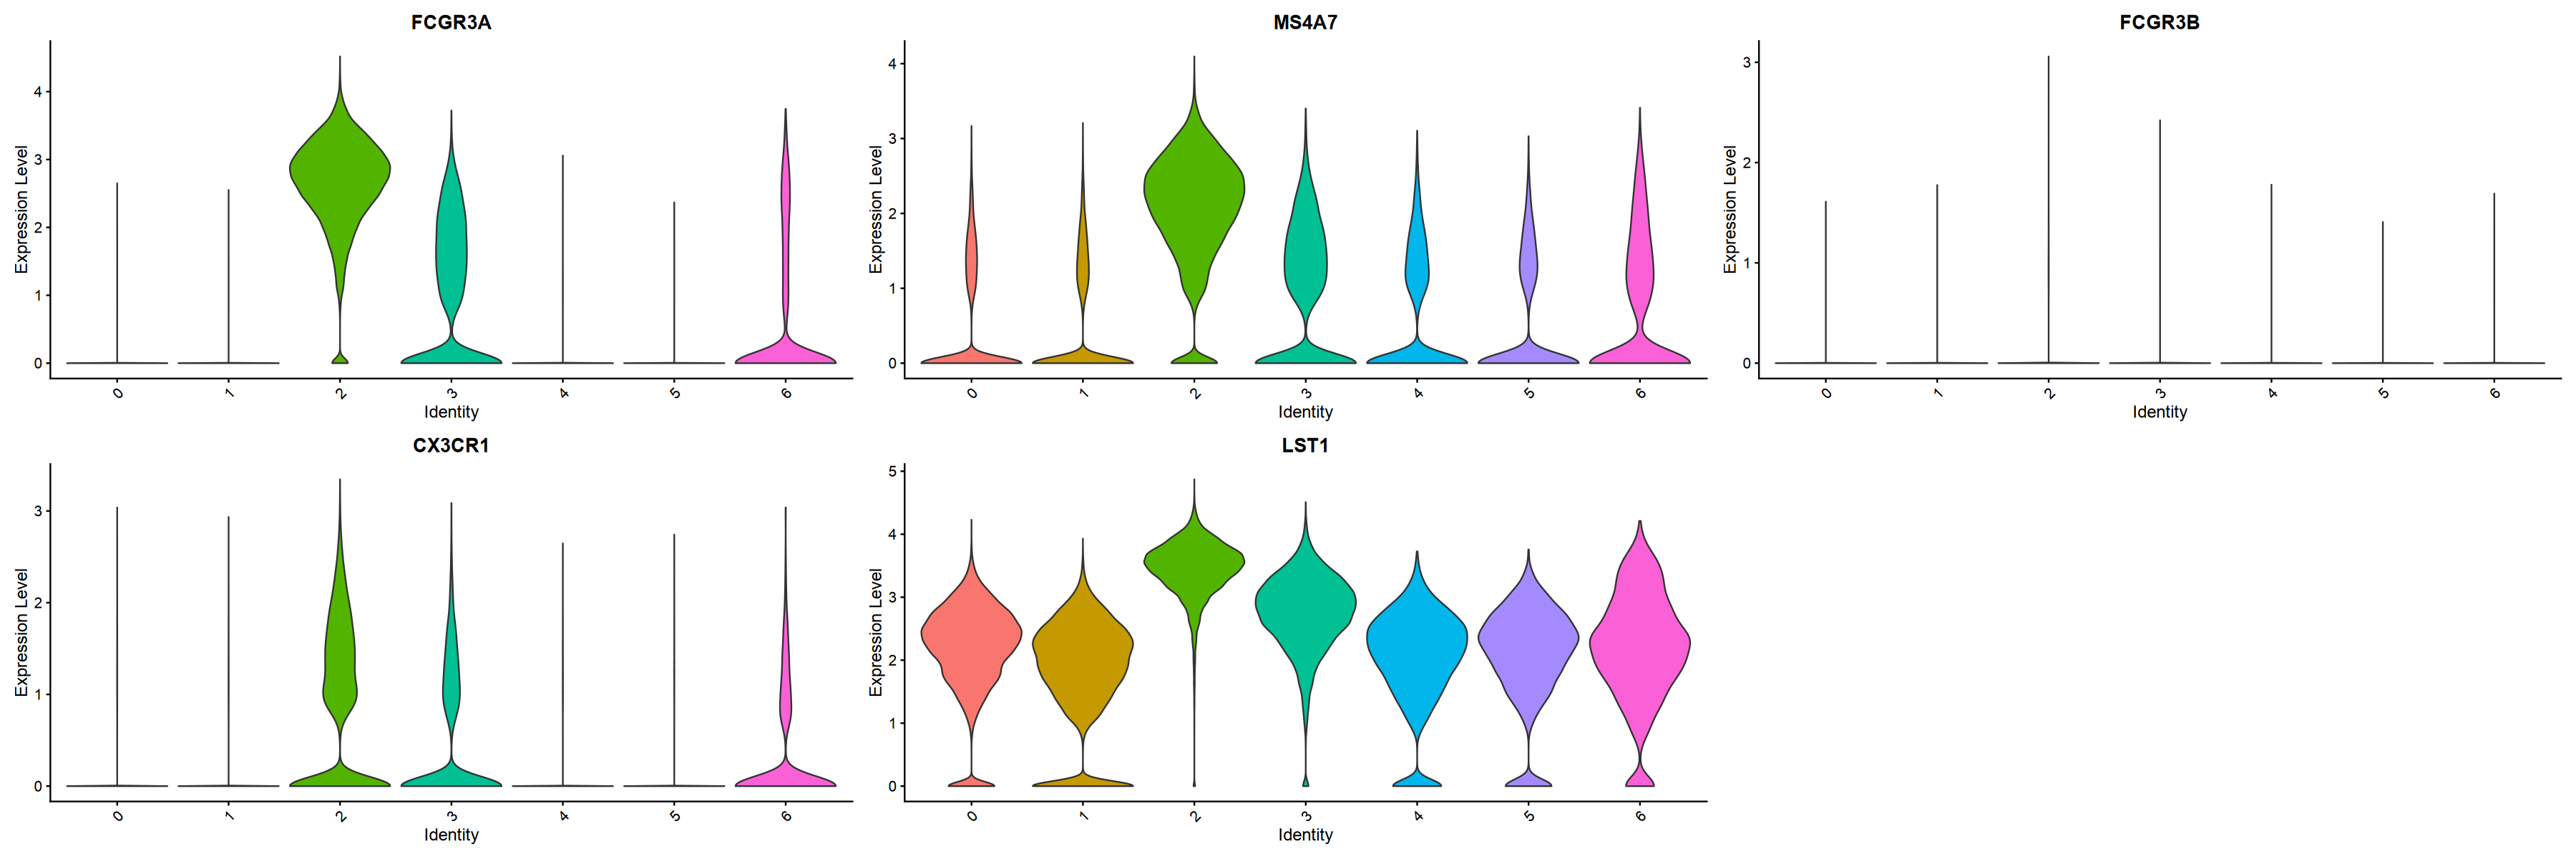

In [68]:
# Define marker genes for each monocyte subtype
markers_classical <- c("CD14", "LYZ", "S100A8", "S100A9", "VCAN", "FCN1")
markers_nonclassical <- c("FCGR3A", "MS4A7", "FCGR3B", "CX3CR1", "LST1")

# Violin plot for classical markers across clusters
VlnPlot(ft, features = markers_classical, group.by = "seurat_clusters", ncol = 3, pt.size = 0)

# Violin plot for non-classical markers across clusters
VlnPlot(ft, features = markers_nonclassical, group.by = "seurat_clusters", ncol = 3, pt.size = 0)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To di

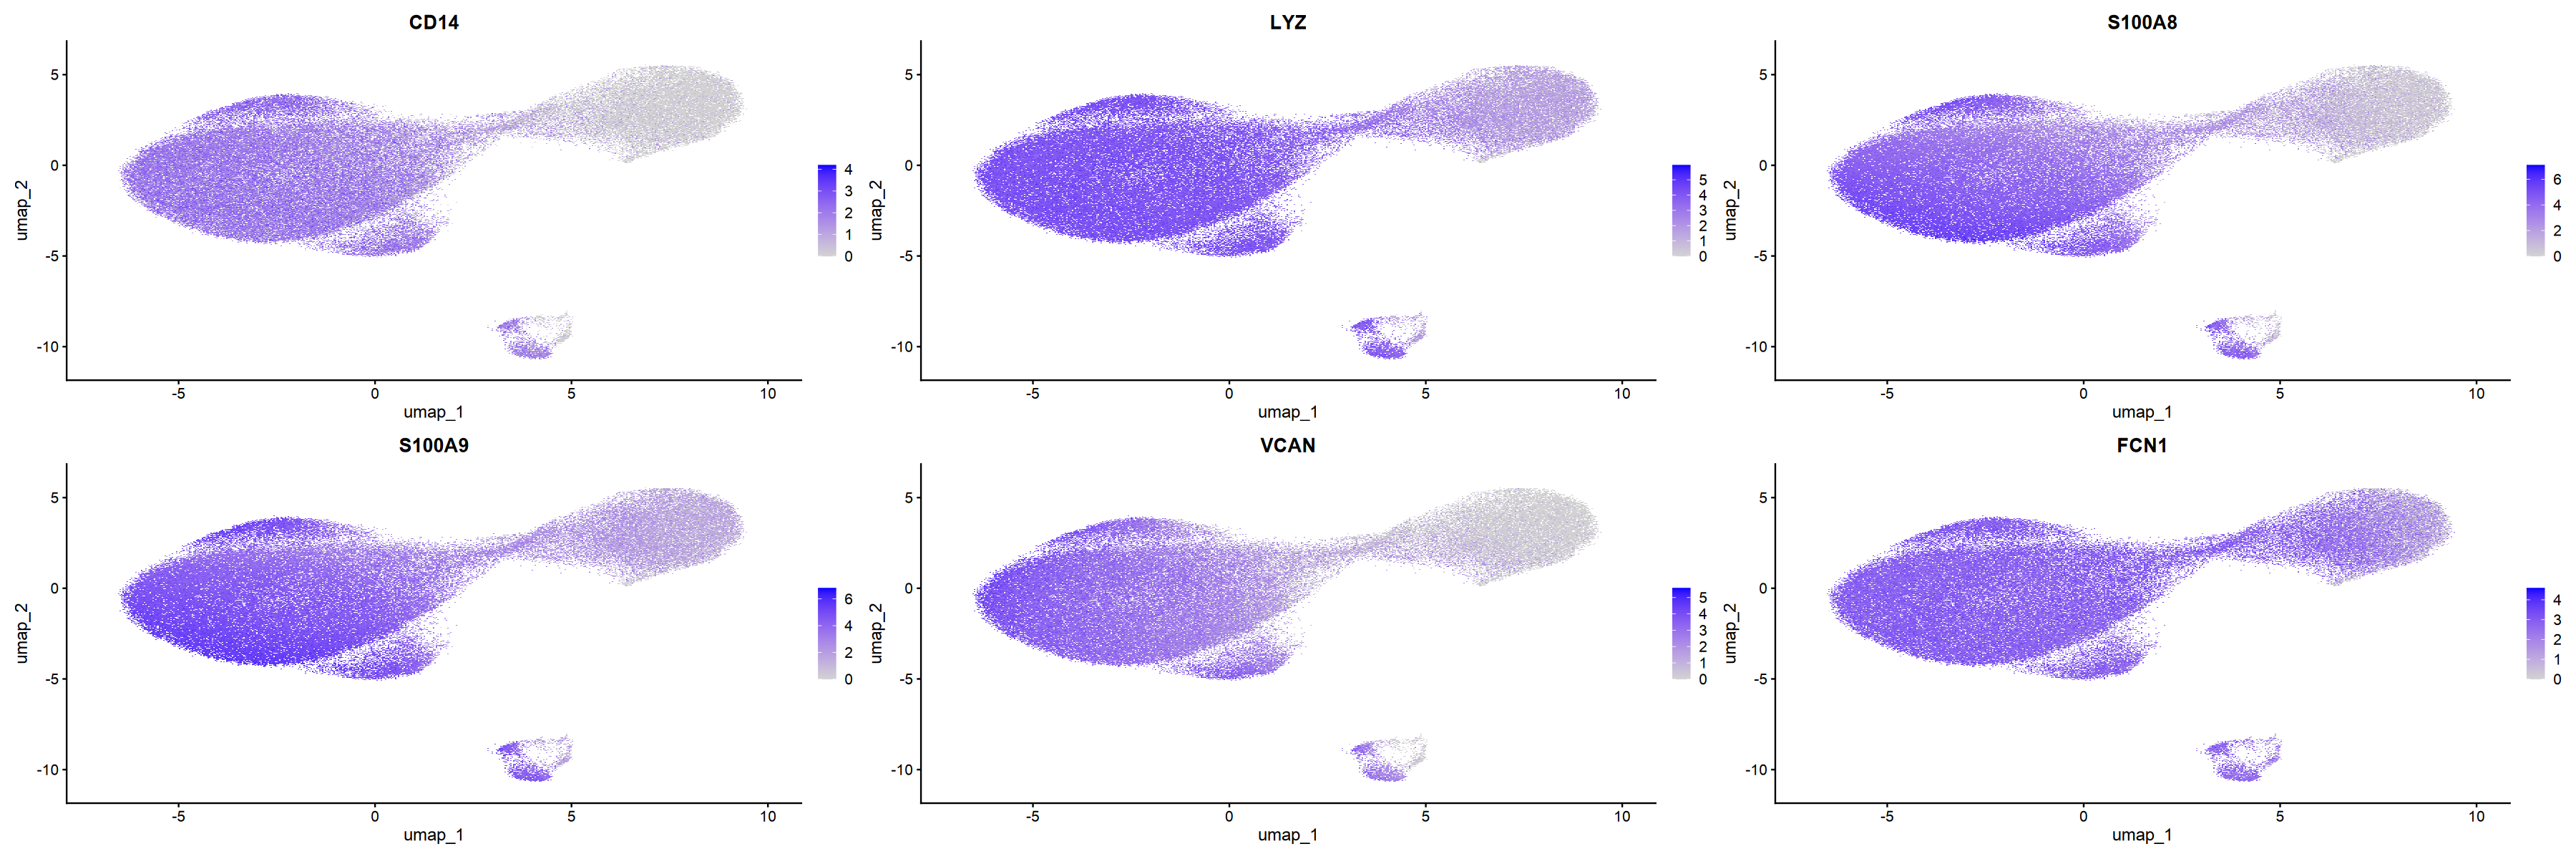

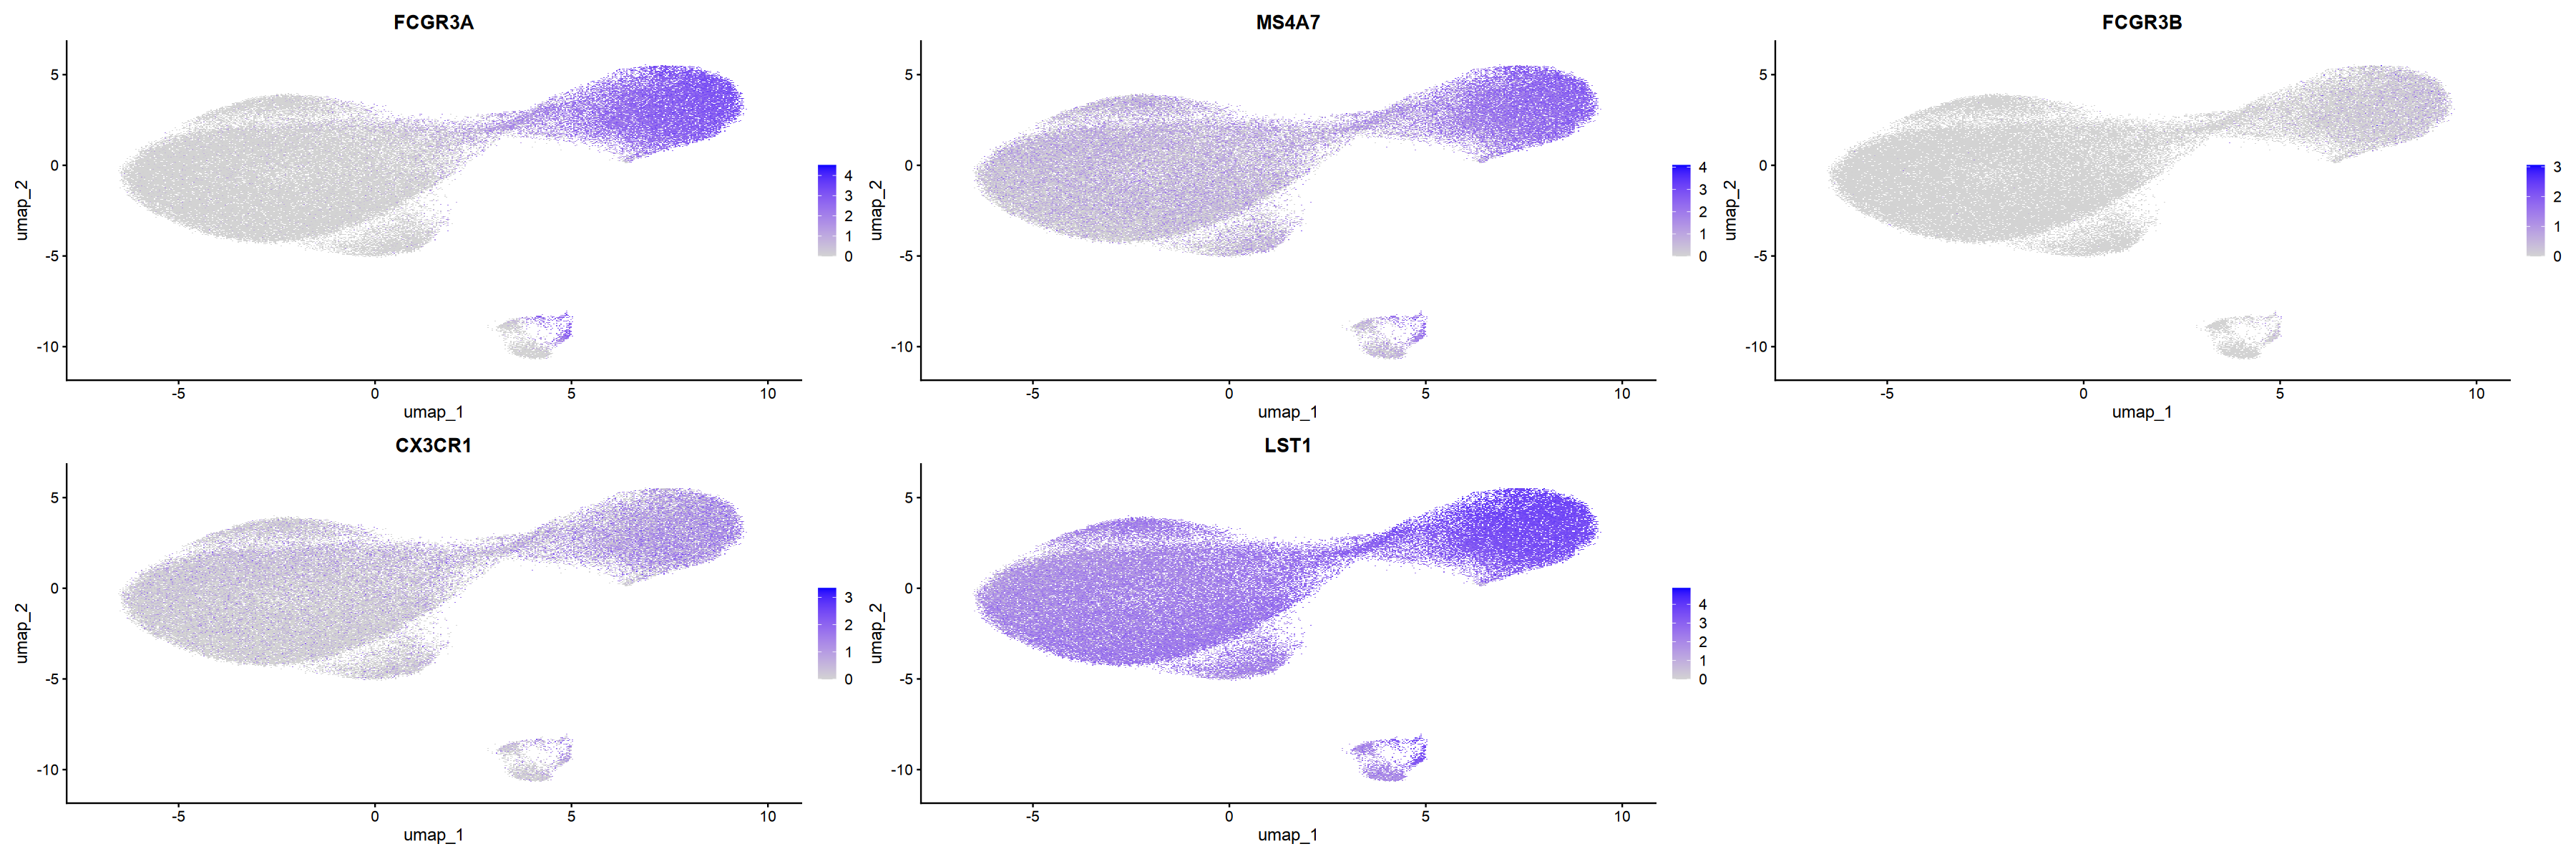

In [71]:
DefaultAssay(ft) <- "RNA"

FeaturePlot(ft, 
            features = markers_classical,  
            reduction = 'umap', ncol=3)


FeaturePlot(ft, 
            features = markers_nonclassical,  
            reduction = 'umap', ncol=3)

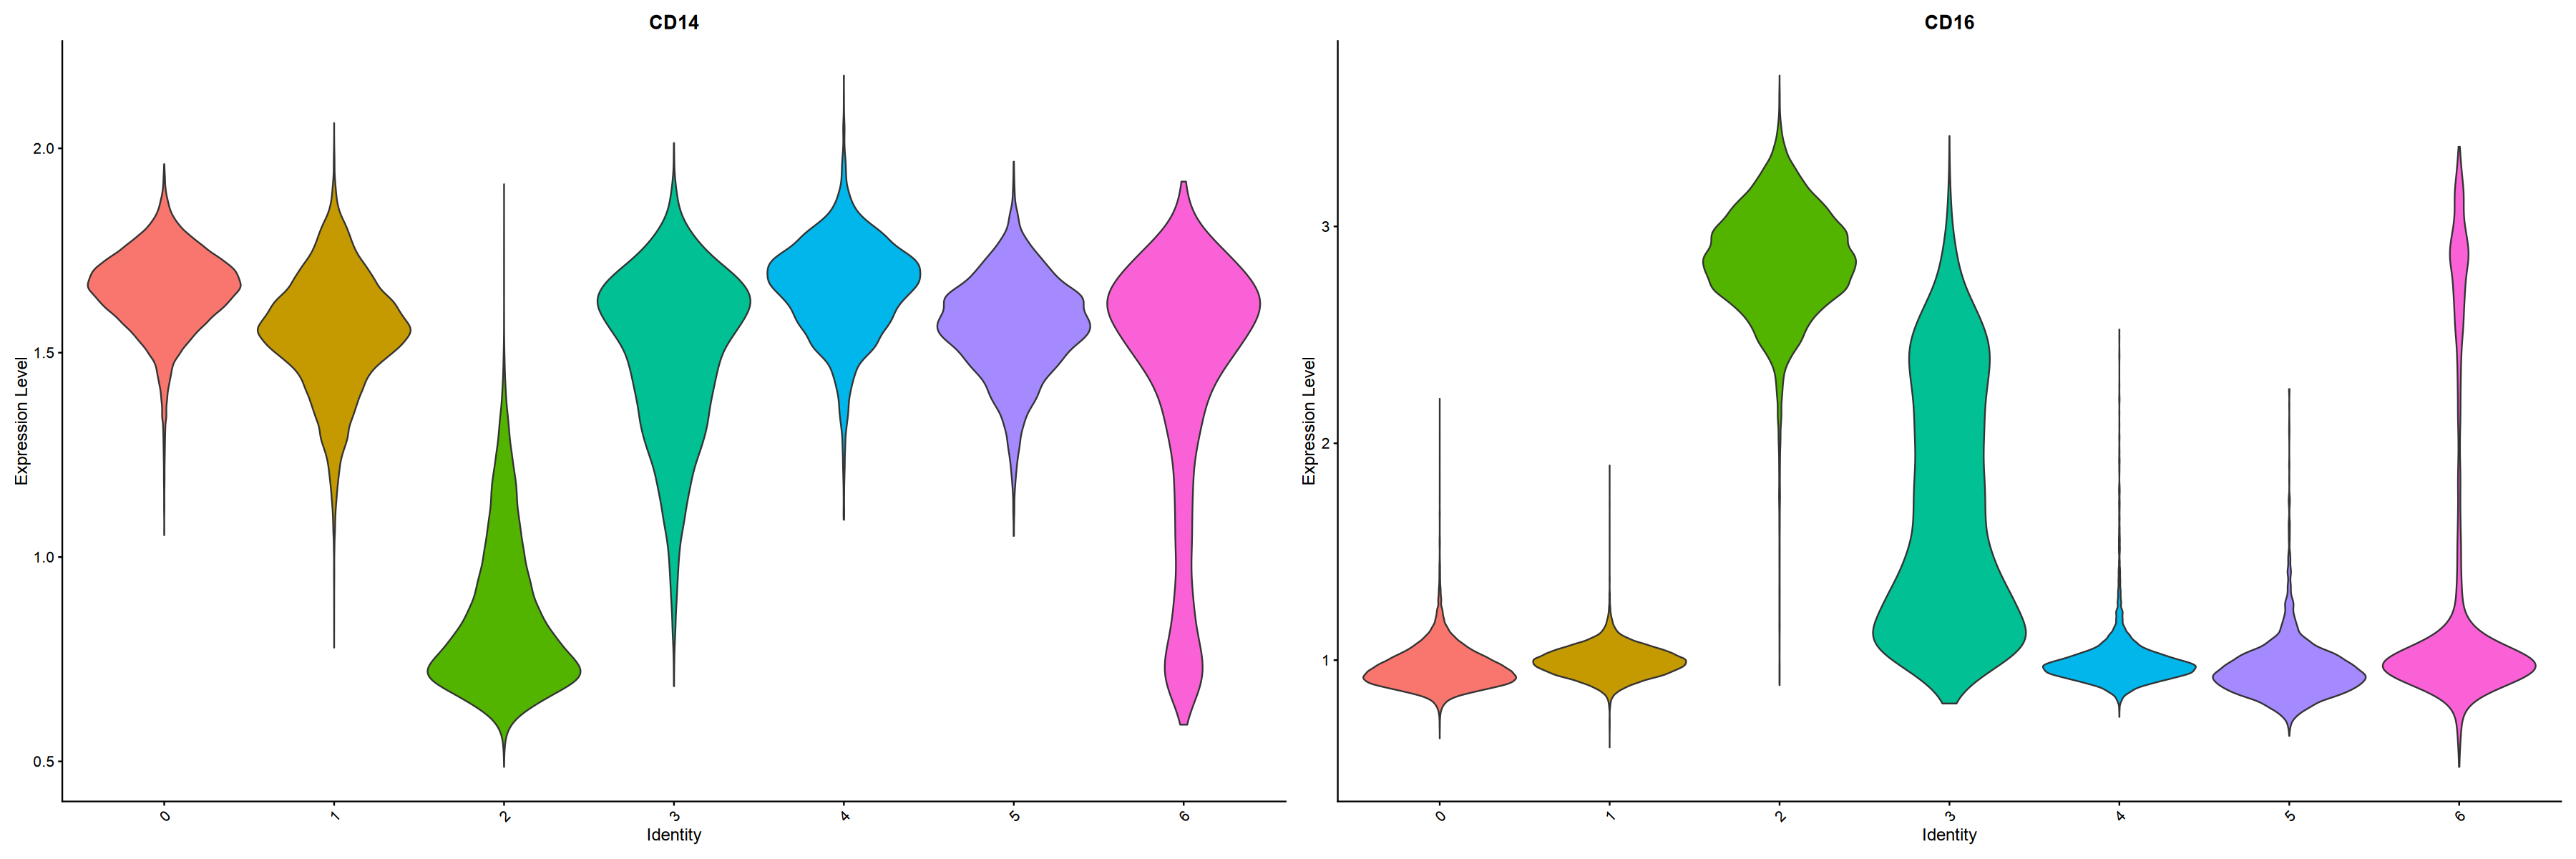

In [69]:
# Set active assay to ADT (protein)
DefaultAssay(ft) <- "impADT"

# Violin plots for ADT markers by cluster (on protein level)
VlnPlot(ft, features = c("CD14", "CD16"), group.by = "seurat_clusters", ncol = 2, pt.size = 0)

Warning message:
“Could not find CD16 in the default search locations, found in ‘impADT’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



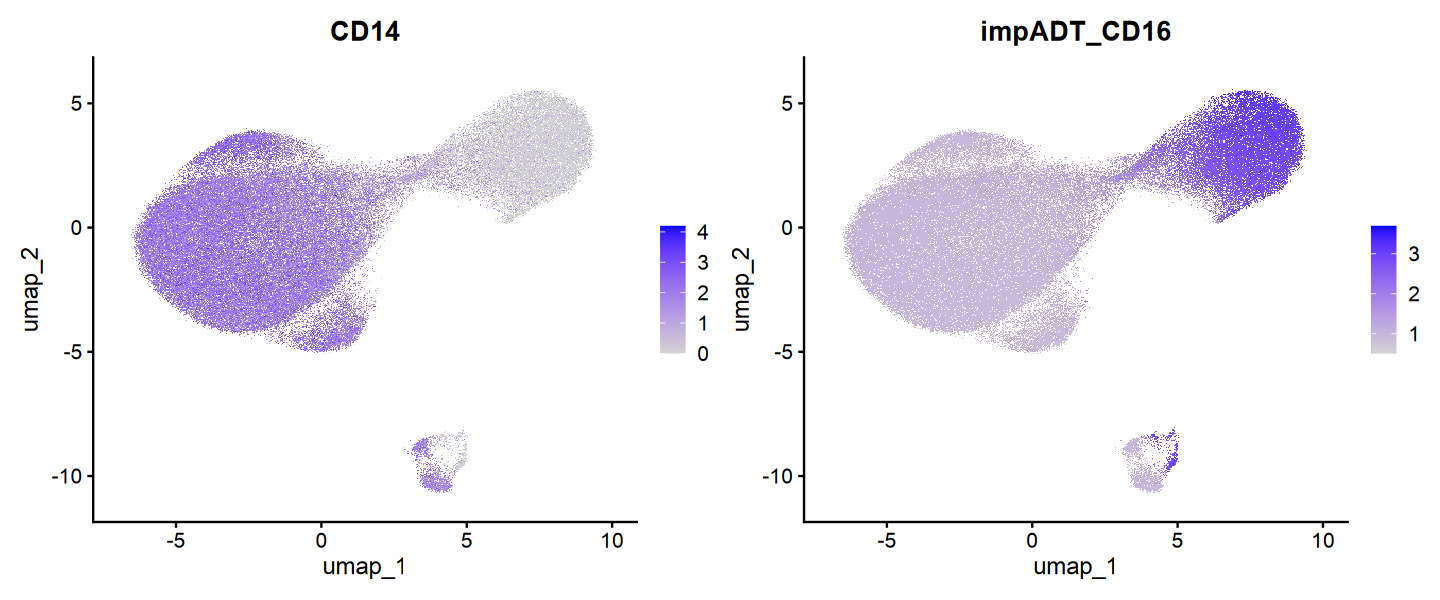

In [73]:
options(repr.plot.width=12, repr.plot.height=5)

FeaturePlot(ft, 
            features = c("CD14", "CD16"),  
            reduction = 'umap', ncol=2)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



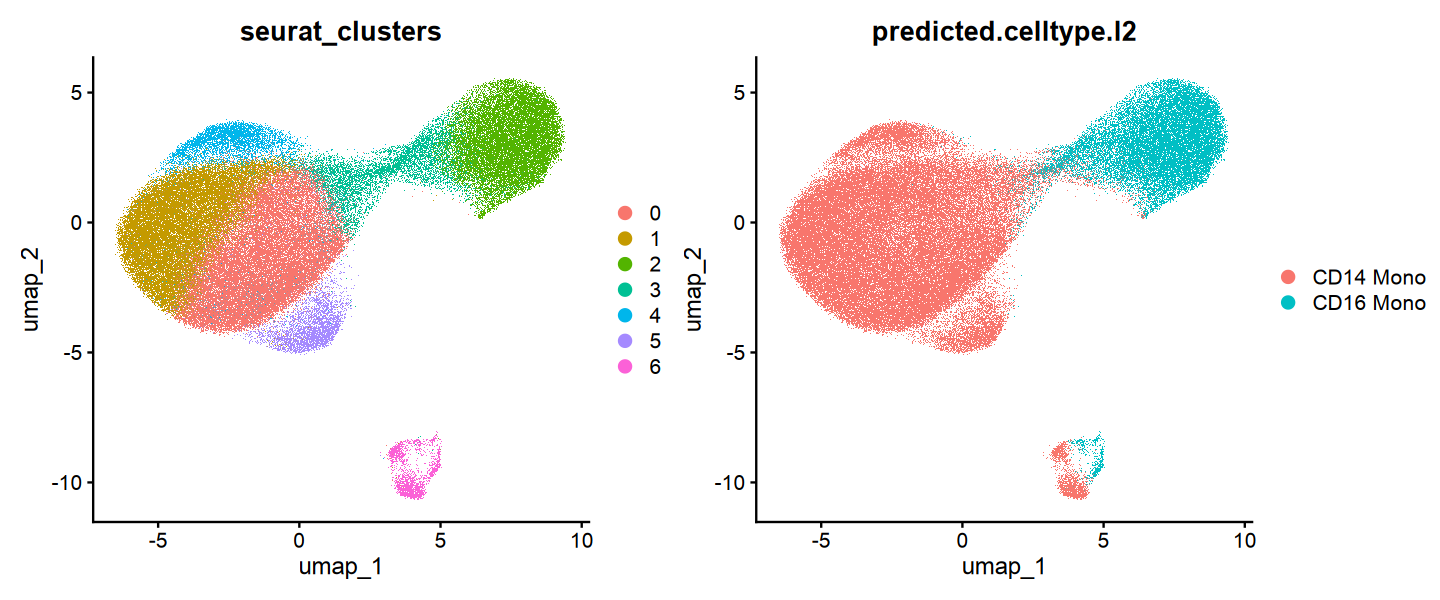

In [74]:
options(repr.plot.width=12, repr.plot.height=5)

DimPlot(ft, reduction = "umap", 
        group.by=c('seurat_clusters','predicted.celltype.l2'),
        ncol=2
       )

In [80]:
# so finally
# first, for seurat cluster 0-5, do classical (0 1 4 5) - intermediate (3) - nonclassical (2)
# then, for cluster 6, use CD14 Mono vs CD16 Mono in predicted.celltype.l2, the CD14 Mono half is Cytototoxic Mono (Mono4), right half is nonclassical

# Initialize with NA
ft@meta.data$celltype_level3 <- NA

# Assign based on seurat_clusters
ft@meta.data$celltype_level3[ft@meta.data$seurat_clusters %in% c(0,1,4,5)] <- "Classical Monocyte"
ft@meta.data$celltype_level3[ft@meta.data$seurat_clusters == 3] <- "Intermediate Monocyte"
ft@meta.data$celltype_level3[ft@meta.data$seurat_clusters == 2] <- "Nonclassical Monocyte"

# For cluster 6, use predicted.celltype.l2 to split
mask6 <- ft@meta.data$seurat_clusters == 6
# (adjust these predicted names as they appear in your object, e.g. 'CD14 Mono' vs 'CD14+ Monocyte')
ft@meta.data$celltype_level3[mask6 & ft@meta.data$predicted.celltype.l2 == "CD14 Mono"] <- "Cytotoxic Monocyte"
ft@meta.data$celltype_level3[mask6 & ft@meta.data$predicted.celltype.l2 == "CD16 Mono"] <- "Nonclassical Monocyte"

   
    Classical Monocyte Cytotoxic Monocyte Intermediate Monocyte
  0              36744                  0                     0
  1              31531                  0                     0
  2                  0                  0                     0
  3                  0                  0                  8109
  4               6435                  0                     0
  5               4632                  0                     0
  6                  0               1766                     0
   
    Nonclassical Monocyte
  0                     0
  1                     0
  2                 21255
  3                     0
  4                     0
  5                     0
  6                   518

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



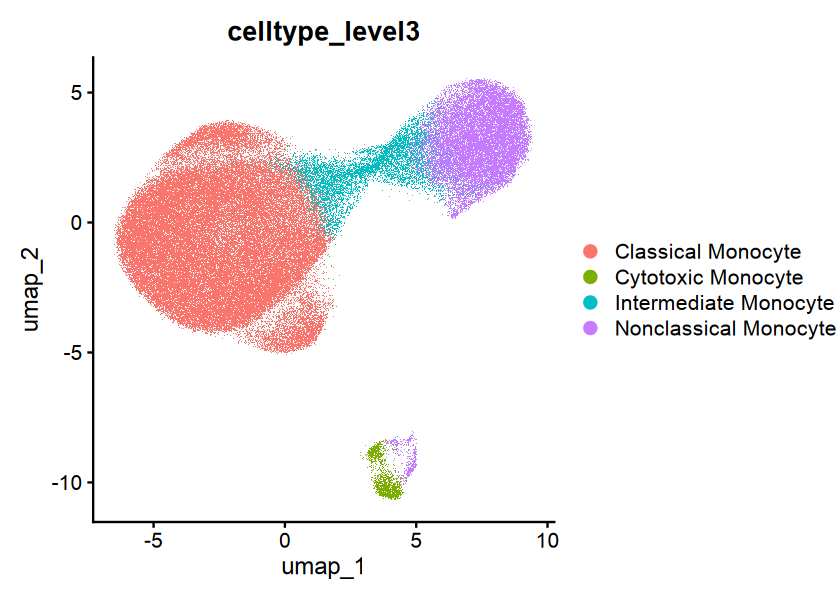

In [82]:
options(repr.plot.width=7, repr.plot.height=5)

DimPlot(ft, reduction = "umap", 
        group.by=c('celltype_level3'),
        ncol=1
       )

In [83]:
# (Optional) check assignment
table(ft@meta.data$celltype_level3)


   Classical Monocyte    Cytotoxic Monocyte Intermediate Monocyte 
                79342                  1766                  8109 
Nonclassical Monocyte 
                21773 

## Save

In [84]:
cell_ordered = c(
    "Classical Monocyte",
    "Intermediate Monocyte",
    "Nonclassical Monocyte",
    "Cytotoxic Monocyte"

)

ft@meta.data[['celltype_level3']] = factor(
    ft@meta.data[['celltype_level3']],
    levels = cell_ordered
)

In [85]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))